In [1]:
# Run this only if datasets is not already installed
# !pip install datasets -q

from datasets import load_dataset

import re
import math
import numpy as np
import pandas as pd

from collections import Counter, defaultdict

In [2]:
dataset = load_dataset(
    "ai4bharat/IndicCorpV2",
    "indiccorp_v2",
    split="hin_Deva",
    streaming=True
)

print("Dataset loaded successfully")

README.md:   0%|          | 0.00/4.01k [00:00<?, ?B/s]

Dataset loaded successfully


In [3]:
first_record = next(iter(dataset))

print(first_record)
print(first_record.keys())

{'text': 'लोगों को बिलों संबंधी सुविधा देना ही उनका काम'}
dict_keys(['text'])


In [4]:
def extract_text(record):
    """
    Extract sentence text from a dataset record.
    """

    possible_columns = [
        "text",
        "sentence",
        "content",
        "document",
        "body"
    ]

    for column in possible_columns:
        if column in record:
            value = record[column]

            if isinstance(value, str):
                return value

    # Fallback:
    # return the first string value found
    for value in record.values():
        if isinstance(value, str):
            return value

    return None

In [5]:
sentences = []

for record in dataset:

    sentence = extract_text(record)

    if sentence is None:
        continue

    sentence = sentence.strip()

    if len(sentence) == 0:
        continue

    sentences.append(sentence)

    if len(sentences) >= 100000:
        break


print("Total sentences collected:", len(sentences))

Total sentences collected: 100000


In [6]:
sentences_df = pd.DataFrame({
    "text": sentences
})

print(sentences_df.shape)

sentences_df.head()

(100000, 1)


,text
0,लोगों को बिलों संबंधी सुविधा देना ही उनका काम
1,इनेलो 1987 में उस वक्त ऐसे ही दोराहे पर खड़ी थ...
2,जहां आई थी तबाही उस घाटी क्षेत्र में खतरा ज्यादा
3,इसके बाद केंद्र की ओर से प्रदेश सरकार को पीएमज...
4,यह पूछने पर कि इस बड़े मैच से पहले उनकी नींद ग...


In [7]:
def tokenize(sentence):

    if not isinstance(sentence, str):
        return []

    sentence = sentence.strip()

    if sentence == "":
        return []

    return sentence.split()

In [8]:
print(sentences_df["text"].iloc[0])
print(tokenize(sentences_df["text"].iloc[0]))

लोगों को बिलों संबंधी सुविधा देना ही उनका काम
['लोगों', 'को', 'बिलों', 'संबंधी', 'सुविधा', 'देना', 'ही', 'उनका', 'काम']


In [9]:
sentences_df["length"] = sentences_df["text"].apply(
    lambda x: len(tokenize(x))
)

sentences_df[["text", "length"]].head()

,text,length
0,लोगों को बिलों संबंधी सुविधा देना ही उनका काम,9
1,इनेलो 1987 में उस वक्त ऐसे ही दोराहे पर खड़ी थ...,231
2,जहां आई थी तबाही उस घाटी क्षेत्र में खतरा ज्यादा,10
3,इसके बाद केंद्र की ओर से प्रदेश सरकार को पीएमज...,41
4,यह पूछने पर कि इस बड़े मैच से पहले उनकी नींद ग...,78


In [10]:
sentences_df["length_bucket"] = pd.cut(
    sentences_df["length"],
    bins=[
        0,
        5,
        10,
        20,
        30,
        50,
        np.inf
    ],
    labels=[
        "1-5",
        "6-10",
        "11-20",
        "21-30",
        "31-50",
        "51+"
    ]
)

print(
    sentences_df["length_bucket"].value_counts()
)

length_bucket
51+      42610
31-50    17338
11-20    16048
6-10     12189
21-30     7973
1-5       3842
Name: count, dtype: int64


In [15]:
def stratified_length_split(
    df,
    dev_size=1000,
    test_size=1000,
    random_state=42
):

    # Shuffle the entire dataset first
    df = df.sample(
        frac=1,
        random_state=random_state
    )

    dev_parts = []
    test_parts = []

    bucket_counts = (
        df["length_bucket"]
        .value_counts()
    )

    total_samples = len(df)

    for i, (bucket, count) in enumerate(
        bucket_counts.items()
    ):

        # Get all samples from this bucket
        bucket_df = df[
            df["length_bucket"] == bucket
        ].sample(
            frac=1,
            random_state=random_state + i
        )

        # Calculate proportional allocation
        dev_n = round(
            count / total_samples * dev_size
        )

        test_n = round(
            count / total_samples * test_size
        )

        # Important:
        # Never request more samples than exist
        if dev_n + test_n > count:

            # Scale proportionally if needed
            total_requested = (
                dev_n + test_n
            )

            dev_n = int(
                count * dev_n
                / total_requested
            )

            test_n = min(
                count - dev_n,
                test_n
            )

        # Add development samples
        dev_part = bucket_df.iloc[
            :dev_n
        ]

        # Add test samples
        test_part = bucket_df.iloc[
            dev_n:
            dev_n + test_n
        ]

        dev_parts.append(
            dev_part
        )

        test_parts.append(
            test_part
        )


    # Combine all buckets
    dev_df = pd.concat(
        dev_parts
    )

    test_df = pd.concat(
        test_parts
    )


    # ------------------------------------------------
    # ADJUST DEVELOPMENT SET TO EXACTLY dev_size
    # ------------------------------------------------

    if len(dev_df) > dev_size:

        dev_df = dev_df.sample(
            n=dev_size,
            random_state=random_state
        )

    elif len(dev_df) < dev_size:

        remaining = df.drop(
            dev_df.index.union(
                test_df.index
            )
        )

        needed = (
            dev_size - len(dev_df)
        )

        extra = remaining.sample(
            n=needed,
            random_state=random_state
        )

        dev_df = pd.concat([
            dev_df,
            extra
        ])


    # ------------------------------------------------
    # ADJUST TEST SET TO EXACTLY test_size
    # ------------------------------------------------

    if len(test_df) > test_size:

        test_df = test_df.sample(
            n=test_size,
            random_state=random_state
        )

    elif len(test_df) < test_size:

        remaining = df.drop(
            dev_df.index.union(
                test_df.index
            )
        )

        needed = (
            test_size - len(test_df)
        )

        extra = remaining.sample(
            n=needed,
            random_state=random_state + 1
        )

        test_df = pd.concat([
            test_df,
            extra
        ])


    # ------------------------------------------------
    # TRAINING DATA
    # ------------------------------------------------

    train_df = df.drop(
        dev_df.index.union(
            test_df.index
        )
    )


    return (
        train_df,
        dev_df,
        test_df
    )

In [16]:
train_df, dev_df, test_df = stratified_length_split(
    sentences_df,
    dev_size=1000,
    test_size=1000,
    random_state=42
)

print("Training size:", len(train_df))
print("Development size:", len(dev_df))
print("Test size:", len(test_df))

Training size: 98000
Development size: 1000
Test size: 1000


In [17]:
train_sentences = train_df["text"].tolist()

dev_sentences = dev_df["text"].tolist()

test_sentences = test_df["text"].tolist()

In [18]:
print(sentences_df["length_bucket"].value_counts())

length_bucket
51+      42610
31-50    17338
11-20    16048
6-10     12189
21-30     7973
1-5       3842
Name: count, dtype: int64


In [19]:
train_sentences = train_df["text"].tolist()

dev_sentences = dev_df["text"].tolist()

test_sentences = test_df["text"].tolist()

In [20]:
UNK_CUTOFF = 1

In [21]:
raw_word_counts = Counter()

for sentence in train_sentences:

    tokens = tokenize(sentence)

    raw_word_counts.update(tokens)

In [22]:
vocab = set()

for word, count in raw_word_counts.items():

    if count > UNK_CUTOFF:
        vocab.add(word)


# Output vocabulary
vocab.add("<UNK>")
vocab.add("</s>")

# <s> is used only as a context token
START_TOKEN = "<s>"
END_TOKEN = "</s>"
UNK_TOKEN = "<UNK>"

V = len(vocab)

print("Vocabulary size:", V)

Vocabulary size: 86878


In [23]:
def map_to_vocabulary(tokens, vocab):

    mapped_tokens = []

    for word in tokens:

        if word in vocab:
            mapped_tokens.append(word)

        else:
            mapped_tokens.append(UNK_TOKEN)

    return mapped_tokens

In [24]:
def build_ngram_counts(
    sentences,
    vocab,
    max_n=4
):

    unigram_counts = Counter()

    ngram_counts = {
        n: Counter()
        for n in range(2, max_n + 1)
    }

    context_counts = {
        n: Counter()
        for n in range(2, max_n + 1)
    }


    for sentence in sentences:

        tokens = tokenize(sentence)

        if len(tokens) == 0:
            continue


        tokens = map_to_vocabulary(
            tokens,
            vocab
        )


        # -------------------------
        # UNIGRAM
        # -------------------------

        unigram_sequence = (
            tokens + [END_TOKEN]
        )

        unigram_counts.update(
            unigram_sequence
        )


        # -------------------------
        # BIGRAM, TRIGRAM, QUADGRAM
        # -------------------------

        for n in range(2, max_n + 1):

            sequence = (
                [START_TOKEN] * (n - 1)
                + tokens
                + [END_TOKEN]
            )


            for i in range(
                len(sequence) - n + 1
            ):

                ngram = tuple(
                    sequence[i:i + n]
                )

                context = ngram[:-1]

                ngram_counts[n][ngram] += 1

                context_counts[n][context] += 1


    return (
        unigram_counts,
        ngram_counts,
        context_counts
    )

In [25]:
(
    unigram_counts,
    ngram_counts,
    context_counts
) = build_ngram_counts(
    train_sentences,
    vocab,
    max_n=4
)

In [26]:
print("Unigram types:", len(unigram_counts))

for n in range(2, 5):

    print(
        f"{n}-gram types:",
        len(ngram_counts[n])
    )

Unigram types: 86878
2-gram types: 1514875
3-gram types: 3710436
4-gram types: 4954019


In [27]:
TOTAL_UNIGRAMS = sum(
    unigram_counts.values()
)

print(TOTAL_UNIGRAMS)

5760013


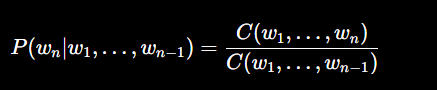

In [28]:
def unsmoothed_probability(
    word,
    context,
    n
):

    # Unigram
    if n == 1:

        return (
            unigram_counts[word]
            / TOTAL_UNIGRAMS
        )


    ngram = context + (word,)

    numerator = (
        ngram_counts[n][ngram]
    )

    denominator = (
        context_counts[n][context]
    )


    if denominator == 0:
        return 0.0


    return (
        numerator / denominator
    )

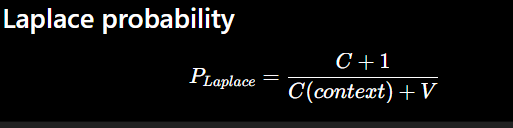

In [29]:
def laplace_probability(
    word,
    context,
    n
):

    # Unigram
    if n == 1:

        return (
            unigram_counts[word] + 1
        ) / (
            TOTAL_UNIGRAMS + V
        )


    ngram = context + (word,)


    return (
        ngram_counts[n][ngram] + 1
    ) / (
        context_counts[n][context] + V
    )

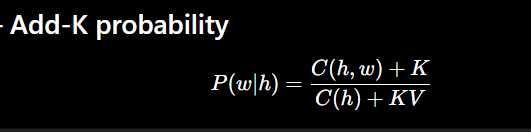

In [30]:
def add_k_probability(
    word,
    context,
    n,
    K
):

    if n == 1:

        return (
            unigram_counts[word] + K
        ) / (
            TOTAL_UNIGRAMS + K * V
        )


    ngram = context + (word,)


    return (
        ngram_counts[n][ngram] + K
    ) / (
        context_counts[n][context]
        + K * V
    )

INTERPOLATED SMOOTHING

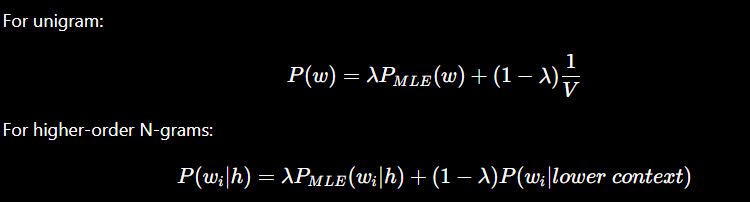

In [31]:
def interpolated_probability(
    word,
    context,
    n,
    lambda_value
):

    # -------------------------
    # UNIGRAM
    # -------------------------

    if n == 1:

        mle_probability = (
            unigram_counts[word]
            / TOTAL_UNIGRAMS
        )

        uniform_probability = (
            1 / V
        )


        return (
            lambda_value
            * mle_probability
            +
            (1 - lambda_value)
            * uniform_probability
        )


    # -------------------------
    # CURRENT ORDER MLE
    # -------------------------

    ngram = context + (word,)

    context_count = (
        context_counts[n][context]
    )


    if context_count > 0:

        mle_probability = (
            ngram_counts[n][ngram]
            / context_count
        )

    else:

        mle_probability = 0.0


    # -------------------------
    # LOWER ORDER
    # -------------------------

    lower_context = context[1:]


    lower_probability = (
        interpolated_probability(
            word,
            lower_context,
            n - 1,
            lambda_value
        )
    )


    return (
        lambda_value
        * mle_probability
        +
        (1 - lambda_value)
        * lower_probability
    )

In [32]:
DISCOUNT = 0.75

In [33]:
def build_kn_statistics(
    ngram_counts,
    max_n=4
):

    # Number of unique followers for each context
    unique_followers = {
        n: defaultdict(set)
        for n in range(2, max_n + 1)
    }


    for n in range(2, max_n + 1):

        for ngram in ngram_counts[n]:

            context = ngram[:-1]

            word = ngram[-1]

            unique_followers[n][context].add(
                word
            )


    unique_follower_counts = {
        n: {
            context: len(words)
            for context, words
            in unique_followers[n].items()
        }
        for n in range(2, max_n + 1)
    }


    # ----------------------------------
    # UNIGRAM CONTINUATION COUNTS
    # ----------------------------------

    predecessors = defaultdict(set)


    for bigram in ngram_counts[2]:

        previous_word = bigram[0]

        word = bigram[1]

        predecessors[word].add(
            previous_word
        )


    unigram_continuation_counts = {
        word: len(previous_words)
        for word, previous_words
        in predecessors.items()
    }


    total_bigram_types = len(
        ngram_counts[2]
    )


    return (
        unique_follower_counts,
        unigram_continuation_counts,
        total_bigram_types
    )

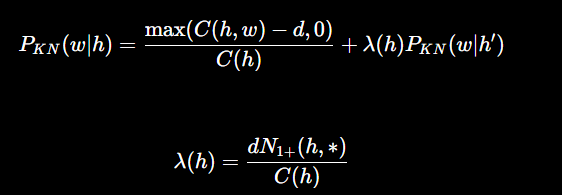

In [34]:
def kneser_ney_probability(
    word,
    context,
    n,
    discount=0.75
):

    # ---------------------------------
    # BASE CASE: UNIGRAM
    # ---------------------------------

    if n == 1:

        continuation_count = (
            unigram_continuation_counts
            .get(word, 0)
        )


        if total_bigram_types == 0:
            return 0.0


        return (
            continuation_count
            / total_bigram_types
        )


    # ---------------------------------
    # CURRENT N-GRAM
    # ---------------------------------

    ngram = context + (word,)

    context_count = (
        context_counts[n][context]
    )


    # Context unseen:
    # back off immediately
    if context_count == 0:

        return kneser_ney_probability(
            word,
            context[1:],
            n - 1,
            discount
        )


    ngram_count = (
        ngram_counts[n][ngram]
    )


    # ---------------------------------
    # DISCOUNTED COUNT
    # ---------------------------------

    first_term = (
        max(
            ngram_count - discount,
            0
        )
        / context_count
    )


    # ---------------------------------
    # NUMBER OF UNIQUE FOLLOWERS
    # ---------------------------------

    unique_followers = (
        unique_follower_counts[n]
        .get(context, 0)
    )


    # ---------------------------------
    # BACKOFF WEIGHT
    # ---------------------------------

    lambda_context = (
        discount
        * unique_followers
        / context_count
    )


    # ---------------------------------
    # LOWER ORDER PROBABILITY
    # ---------------------------------

    lower_probability = (
        kneser_ney_probability(
            word,
            context[1:],
            n - 1,
            discount
        )
    )


    return (
        first_term
        +
        lambda_context
        * lower_probability
    )

In [35]:
def prepare_sentence(
    sentence,
    vocab,
    n
):

    tokens = tokenize(
        sentence
    )

    tokens = map_to_vocabulary(
        tokens,
        vocab
    )


    if n == 1:

        return (
            tokens
            + [END_TOKEN]
        )


    return (
        [START_TOKEN] * (n - 1)
        +
        tokens
        +
        [END_TOKEN]
    )

In [36]:
def sentence_log_probability(
    sentence,
    n,
    smoothing_method,
    K=0.1,
    lambda_value=0.7,
    discount=0.75
):

    sequence = prepare_sentence(
        sentence,
        vocab,
        n
    )


    log_probability = 0.0


    # =================================
    # UNIGRAM
    # =================================

    if n == 1:

        for word in sequence:


            if smoothing_method == "unsmoothed":

                probability = (
                    unsmoothed_probability(
                        word,
                        (),
                        1
                    )
                )


            elif smoothing_method == "laplace":

                probability = (
                    laplace_probability(
                        word,
                        (),
                        1
                    )
                )


            elif smoothing_method == "add_k":

                probability = (
                    add_k_probability(
                        word,
                        (),
                        1,
                        K
                    )
                )


            elif smoothing_method == "interpolated":

                probability = (
                    interpolated_probability(
                        word,
                        (),
                        1,
                        lambda_value
                    )
                )


            elif smoothing_method == "kneser_ney":

                probability = (
                    kneser_ney_probability(
                        word,
                        (),
                        1,
                        discount
                    )
                )


            else:

                raise ValueError(
                    "Unknown smoothing method"
                )


            if probability <= 0:

                return float("-inf")


            log_probability += (
                math.log(probability)
            )


        return log_probability


    # =================================
    # BIGRAM / TRIGRAM / QUADGRAM
    # =================================

    for i in range(
        n - 1,
        len(sequence)
    ):

        word = sequence[i]


        context = tuple(
            sequence[
                i - (n - 1):i
            ]
        )


        if smoothing_method == "unsmoothed":

            probability = (
                unsmoothed_probability(
                    word,
                    context,
                    n
                )
            )


        elif smoothing_method == "laplace":

            probability = (
                laplace_probability(
                    word,
                    context,
                    n
                )
            )


        elif smoothing_method == "add_k":

            probability = (
                add_k_probability(
                    word,
                    context,
                    n,
                    K
                )
            )


        elif smoothing_method == "interpolated":

            probability = (
                interpolated_probability(
                    word,
                    context,
                    n,
                    lambda_value
                )
            )


        elif smoothing_method == "kneser_ney":

            probability = (
                kneser_ney_probability(
                    word,
                    context,
                    n,
                    discount
                )
            )


        else:

            raise ValueError(
                "Unknown smoothing method"
            )


        if probability <= 0:

            return float("-inf")


        log_probability += (
            math.log(probability)
        )


    return log_probability

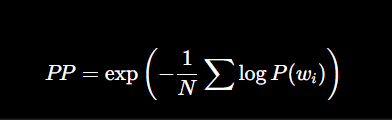

In [37]:
def calculate_perplexity(
    sentences,
    n,
    smoothing_method,
    K=0.1,
    lambda_value=0.7,
    discount=0.75,
    verbose=False
):

    total_log_probability = 0.0

    total_predictions = 0


    for index, sentence in enumerate(sentences):

        tokens = tokenize(
            sentence
        )


        if len(tokens) == 0:
            continue


        log_prob = (
            sentence_log_probability(
                sentence,
                n,
                smoothing_method,
                K,
                lambda_value,
                discount
            )
        )


        # Zero probability means
        # infinite perplexity
        if log_prob == float("-inf"):

            return float("inf")


        total_log_probability += (
            log_prob
        )


        # Number of predicted tokens
        total_predictions += (
            len(tokens) + 1
        )


        if verbose:

            if (
                (index + 1) % 500
                == 0
            ):

                print(
                    f"Processed {index + 1} sentences"
                )


    perplexity = math.exp(
        -total_log_probability
        / total_predictions
    )


    return perplexity

In [38]:
pp = calculate_perplexity(
    test_sentences,
    n=2,
    smoothing_method="laplace",
    verbose=True
)

print(
    "Bigram Laplace Perplexity:",
    pp
)

Processed 500 sentences
Processed 1000 sentences
Bigram Laplace Perplexity: 3544.5065773030706


In [39]:
K_VALUES = [
    0.01,
    0.05,
    0.1,
    0.25,
    0.5,
    0.75
]

In [40]:
def tune_k(
    dev_sentences,
    n,
    k_values
):

    results = []


    for K in k_values:

        pp = calculate_perplexity(
            dev_sentences,
            n=n,
            smoothing_method="add_k",
            K=K
        )


        results.append({
            "K": K,
            "Development Perplexity": pp
        })


        print(
            f"N={n}, "
            f"K={K}, "
            f"PP={pp}"
        )


    results_df = pd.DataFrame(
        results
    )


    results_df = results_df.sort_values(
        by="Development Perplexity"
    )


    best_K = (
        results_df
        .iloc[0]["K"]
    )


    return (
        best_K,
        results_df
    )

In [41]:
best_k_values = {}

k_tuning_results = {}


for n in range(1, 5):

    print("\n")
    print("=" * 60)

    print(
        f"Tuning K for {n}-gram"
    )

    print("=" * 60)


    best_K, tuning_df = tune_k(
        dev_sentences,
        n,
        K_VALUES
    )


    best_k_values[n] = best_K

    k_tuning_results[n] = tuning_df


    print("\nBest K:")
    print(best_K)



Tuning K for 1-gram
N=1, K=0.01, PP=1641.6951086144115
N=1, K=0.05, PP=1641.9182582548538
N=1, K=0.1, PP=1642.206094448792
N=1, K=0.25, PP=1643.1254504158378
N=1, K=0.5, PP=1644.8250300219922
N=1, K=0.75, PP=1646.7057013677124

Best K:
0.01


Tuning K for 2-gram
N=2, K=0.01, PP=641.4040227010241
N=2, K=0.05, PP=953.3087384659916
N=2, K=0.1, PP=1225.402106091986
N=2, K=0.25, PP=1826.7118506346255
N=2, K=0.5, PP=2581.8507762276336
N=2, K=0.75, PP=3206.741377317532

Best K:
0.01


Tuning K for 3-gram
N=3, K=0.01, PP=5841.387083579248
N=3, K=0.05, PP=9724.598512969178
N=3, K=0.1, PP=12500.082734411093
N=3, K=0.25, PP=17616.883088512157
N=3, K=0.5, PP=22778.407705752084
N=3, K=0.75, PP=26335.226761122

Best K:
0.01


Tuning K for 4-gram
N=4, K=0.01, PP=31104.314962841847
N=4, K=0.05, PP=39435.41535681309
N=4, K=0.1, PP=43863.09558646636
N=4, K=0.25, PP=50398.95078604993
N=4, K=0.5, PP=55697.41659330817
N=4, K=0.75, PP=58842.951977976394

Best K:
0.01


In [42]:
for n in range(1, 5):

    print(f"\n{n}-GRAM")

    print(
        k_tuning_results[n]
    )


1-GRAM
      K  Development Perplexity
0  0.01             1641.695109
1  0.05             1641.918258
2  0.10             1642.206094
3  0.25             1643.125450
4  0.50             1644.825030
5  0.75             1646.705701

2-GRAM
      K  Development Perplexity
0  0.01              641.404023
1  0.05              953.308738
2  0.10             1225.402106
3  0.25             1826.711851
4  0.50             2581.850776
5  0.75             3206.741377

3-GRAM
      K  Development Perplexity
0  0.01             5841.387084
1  0.05             9724.598513
2  0.10            12500.082734
3  0.25            17616.883089
4  0.50            22778.407706
5  0.75            26335.226761

4-GRAM
      K  Development Perplexity
0  0.01            31104.314963
1  0.05            39435.415357
2  0.10            43863.095586
3  0.25            50398.950786
4  0.50            55697.416593
5  0.75            58842.951978


In [43]:
LAMBDA_VALUES = [
    0.1,
    0.2,
    0.3,
    0.4,
    0.5,
    0.6,
    0.7,
    0.8,
    0.9
]

In [44]:
def tune_lambda(
    dev_sentences,
    n,
    lambda_values
):

    results = []


    for lambda_value in lambda_values:


        pp = calculate_perplexity(
            dev_sentences,
            n=n,
            smoothing_method="interpolated",
            lambda_value=lambda_value
        )


        results.append({
            "Lambda": lambda_value,
            "Development Perplexity": pp
        })


        print(
            f"N={n}, "
            f"Lambda={lambda_value}, "
            f"PP={pp}"
        )


    results_df = pd.DataFrame(
        results
    )


    results_df = results_df.sort_values(
        by="Development Perplexity"
    )


    best_lambda = (
        results_df
        .iloc[0]["Lambda"]
    )


    return (
        best_lambda,
        results_df
    )

In [45]:
best_lambda_values = {}

lambda_tuning_results = {}


for n in range(1, 5):

    print("\n")
    print("=" * 60)

    print(
        f"Tuning Lambda for {n}-gram"
    )

    print("=" * 60)


    best_lambda, tuning_df = tune_lambda(
        dev_sentences,
        n,
        LAMBDA_VALUES
    )


    best_lambda_values[n] = best_lambda

    lambda_tuning_results[n] = tuning_df


    print("\nBest Lambda:")
    print(best_lambda)



Tuning Lambda for 1-gram
N=1, Lambda=0.1, PP=8172.680290275083
N=1, Lambda=0.2, PP=5070.800284836798
N=1, Lambda=0.3, PP=3783.3770972356306
N=1, Lambda=0.4, PP=3062.05898678851
N=1, Lambda=0.5, PP=2597.3331021643967
N=1, Lambda=0.6, PP=2272.9645021951774
N=1, Lambda=0.7, PP=2035.297286353795
N=1, Lambda=0.8, PP=1856.7888796143764
N=1, Lambda=0.9, PP=1724.008803127193

Best Lambda:
0.9


Tuning Lambda for 2-gram
N=2, Lambda=0.1, PP=1385.8006556407074
N=2, Lambda=0.2, PP=813.0734470228247
N=2, Lambda=0.3, PP=602.290856885526
N=2, Lambda=0.4, PP=493.9073044090853
N=2, Lambda=0.5, PP=430.2814259043825
N=2, Lambda=0.6, PP=391.60194126712184
N=2, Lambda=0.7, PP=370.228048554928
N=2, Lambda=0.8, PP=365.13967528442714
N=2, Lambda=0.9, PP=386.45114426312

Best Lambda:
0.8


Tuning Lambda for 3-gram
N=3, Lambda=0.1, PP=828.6471935718431
N=3, Lambda=0.2, PP=521.830963184926
N=3, Lambda=0.3, PP=420.6100511564778
N=3, Lambda=0.4, PP=380.35645830573606
N=3, Lambda=0.5, PP=371.599724676221
N=3, Lam

In [46]:
parameter_results = []

for n in range(1, 5):

    parameter_results.append({
        "N-gram": n,
        "Best K": best_k_values[n],
        "Best Lambda": best_lambda_values[n]
    })


parameter_df = pd.DataFrame(
    parameter_results
)

parameter_df

,N-gram,Best K,Best Lambda
0,1,0.01,0.9
1,2,0.01,0.8
2,3,0.01,0.5
3,4,0.01,0.3


In [48]:
def build_kn_statistics(
    ngram_counts,
    max_n=4
):

    # Number of unique followers for every context
    unique_followers = {
        n: defaultdict(set)
        for n in range(2, max_n + 1)
    }


    for n in range(2, max_n + 1):

        for ngram in ngram_counts[n]:

            context = ngram[:-1]

            word = ngram[-1]

            unique_followers[n][context].add(
                word
            )


    # Convert sets to counts
    unique_follower_counts = {
        n: {
            context: len(words)
            for context, words
            in unique_followers[n].items()
        }
        for n in range(2, max_n + 1)
    }


    # --------------------------------
    # UNIGRAM CONTINUATION COUNTS
    # --------------------------------

    predecessors = defaultdict(set)


    for bigram in ngram_counts[2]:

        previous_word = bigram[0]

        word = bigram[1]

        predecessors[word].add(
            previous_word
        )


    unigram_continuation_counts = {
        word: len(previous_words)
        for word, previous_words
        in predecessors.items()
    }


    # Total number of distinct bigram types
    total_bigram_types = len(
        ngram_counts[2]
    )


    return (
        unique_follower_counts,
        unigram_continuation_counts,
        total_bigram_types
    )

In [50]:
(
    unique_follower_counts,
    unigram_continuation_counts,
    total_bigram_types
) = build_kn_statistics(
    ngram_counts,
    max_n=4
)

In [51]:
print(
    "Number of contexts:",
    sum(
        len(unique_follower_counts[n])
        for n in range(2, 5)
    )
)

print(
    "Words with continuation counts:",
    len(unigram_continuation_counts)
)

print(
    "Total distinct bigrams:",
    total_bigram_types
)

Number of contexts: 5260841
Words with continuation counts: 86878
Total distinct bigrams: 1514875


In [52]:
test_word = list(vocab)[0]

print(
    kneser_ney_probability(
        word=test_word,
        context=(),
        n=1,
        discount=0.75
    )
)

2.6404818879445497e-06


In [53]:
methods = [
    "unsmoothed",
    "laplace",
    "add_k",
    "interpolated",
    "kneser_ney"
]


results = []


for n in range(1, 5):

    for method in methods:

        print("\n")
        print("=" * 70)

        print(
            f"Running {n}-gram "
            f"with {method}"
        )

        print("=" * 70)


        # Get tuned parameters
        K = best_k_values[n]

        lambda_value = (
            best_lambda_values[n]
        )


        perplexity = (
            calculate_perplexity(
                test_sentences,
                n=n,
                smoothing_method=method,
                K=K,
                lambda_value=lambda_value,
                discount=0.75,
                verbose=True
            )
        )


        results.append({
            "Language Model":
                f"{n}-gram",

            "N":
                n,

            "Smoothing":
                method,

            "K":
                K if method == "add_k"
                else np.nan,

            "Lambda":
                lambda_value
                if method == "interpolated"
                else np.nan,

            "Discount":
                0.75
                if method == "kneser_ney"
                else np.nan,

            "Test Perplexity":
                perplexity
        })


        print(
            f"\nFinal Perplexity: "
            f"{perplexity}"
        )



Running 1-gram with unsmoothed
Processed 500 sentences
Processed 1000 sentences

Final Perplexity: 1605.8268531412643


Running 1-gram with laplace
Processed 500 sentences
Processed 1000 sentences

Final Perplexity: 1613.21359723919


Running 1-gram with add_k
Processed 500 sentences
Processed 1000 sentences

Final Perplexity: 1605.8851603240282


Running 1-gram with interpolated
Processed 500 sentences
Processed 1000 sentences

Final Perplexity: 1688.9490655224533


Running 1-gram with kneser_ney
Processed 500 sentences
Processed 1000 sentences

Final Perplexity: 2326.8139610624708


Running 2-gram with unsmoothed

Final Perplexity: inf


Running 2-gram with laplace
Processed 500 sentences
Processed 1000 sentences

Final Perplexity: 3544.5065773030706


Running 2-gram with add_k
Processed 500 sentences
Processed 1000 sentences

Final Perplexity: 595.7331858899473


Running 2-gram with interpolated
Processed 500 sentences
Processed 1000 sentences

Final Perplexity: 344.7348391803244


In [54]:
results_df = pd.DataFrame(
    results
)

results_df

,Language Model,N,Smoothing,K,Lambda,Discount,Test Perplexity
0,1-gram,1,unsmoothed,NaN,NaN,NaN,1.605827e+03
1,1-gram,1,laplace,NaN,NaN,NaN,1.613214e+03
2,1-gram,1,add_k,0.01,NaN,NaN,1.605885e+03
3,1-gram,1,interpolated,NaN,0.9,NaN,1.688949e+03
4,1-gram,1,kneser_ney,NaN,NaN,0.75,2.326814e+03
5,2-gram,2,unsmoothed,NaN,NaN,NaN,inf
6,2-gram,2,laplace,NaN,NaN,NaN,3.544507e+03
7,2-gram,2,add_k,0.01,NaN,NaN,5.957332e+02
8,2-gram,2,interpolated,NaN,0.8,NaN,3.447348e+02
9,2-gram,2,kneser_ney,NaN,NaN,0.75,2.987152e+02


In [55]:
results_sorted = results_df.sort_values(
    by="Test Perplexity",
    ascending=True
)

results_sorted

,Language Model,N,Smoothing,K,Lambda,Discount,Test Perplexity
14,3-gram,3,kneser_ney,NaN,NaN,0.75,2.522582e+02
19,4-gram,4,kneser_ney,NaN,NaN,0.75,2.673068e+02
9,2-gram,2,kneser_ney,NaN,NaN,0.75,2.987152e+02
8,2-gram,2,interpolated,NaN,0.8,NaN,3.447348e+02
13,3-gram,3,interpolated,NaN,0.5,NaN,3.487087e+02
18,4-gram,4,interpolated,NaN,0.3,NaN,4.678206e+02
7,2-gram,2,add_k,0.01,NaN,NaN,5.957332e+02
0,1-gram,1,unsmoothed,NaN,NaN,NaN,1.605827e+03
2,1-gram,1,add_k,0.01,NaN,NaN,1.605885e+03
1,1-gram,1,laplace,NaN,NaN,NaN,1.613214e+03


In [56]:
results_sorted = results_df.sort_values(
    by="Test Perplexity",
    ascending=True
)

results_sorted

,Language Model,N,Smoothing,K,Lambda,Discount,Test Perplexity
14,3-gram,3,kneser_ney,NaN,NaN,0.75,2.522582e+02
19,4-gram,4,kneser_ney,NaN,NaN,0.75,2.673068e+02
9,2-gram,2,kneser_ney,NaN,NaN,0.75,2.987152e+02
8,2-gram,2,interpolated,NaN,0.8,NaN,3.447348e+02
13,3-gram,3,interpolated,NaN,0.5,NaN,3.487087e+02
18,4-gram,4,interpolated,NaN,0.3,NaN,4.678206e+02
7,2-gram,2,add_k,0.01,NaN,NaN,5.957332e+02
0,1-gram,1,unsmoothed,NaN,NaN,NaN,1.605827e+03
2,1-gram,1,add_k,0.01,NaN,NaN,1.605885e+03
1,1-gram,1,laplace,NaN,NaN,NaN,1.613214e+03
